# GRUPA A

# Zadanie 1

In [168]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [153]:
BASE = "https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/"
df = pd.read_csv(BASE + "Ecdat/Computers.csv").drop(columns="rownames")

df

,price,speed,hd,ram,screen,cd,multi,premium,ads,trend
0,1499,25,80,4,14,no,no,yes,94,1
1,1795,33,85,2,14,no,no,yes,94,1
2,1595,25,170,4,15,no,no,yes,94,1
3,1849,25,170,8,14,no,no,no,94,1
4,3295,33,340,16,14,no,no,yes,94,1
...,...,...,...,...,...,...,...,...,...,...
6254,1690,100,528,8,15,no,no,yes,39,35
6255,2223,66,850,16,15,yes,yes,yes,39,35
6256,2654,100,1200,24,15,yes,no,yes,39,35
6257,2195,100,850,16,15,yes,no,yes,39,35


In [154]:
print(f"WYMIARY: {df.shape}")
print(f"BRAKI:\n{df.isna().sum()}")
print(f"DUPLIKATY: {df.duplicated().sum()}")
print(f"RAM: {df['ram'].value_counts()}")

WYMIARY: (6259, 10)
BRAKI:
price      0
speed      0
hd         0
ram        0
screen     0
cd         0
multi      0
premium    0
ads        0
trend      0
dtype: int64
DUPLIKATY: 76
RAM: ram
8     2320
4     2236
16     996
2      394
24     297
32      16
Name: count, dtype: int64


Kolumna RAM ma 6 różnych wartości, wartość 8 występuje najczęściej

In [155]:
df["usd_per_mhz"] = df["price"] / df["speed"]

print(f"ŚREDNIA:{df['usd_per_mhz'].mean().round(2)}")
print(f"MINIMUM:{df['usd_per_mhz'].min().round(2)}")
print(f"MAXIMUM:{df['usd_per_mhz'].max().round(2)}")


ŚREDNIA:48.51
MINIMUM:13.95
MAXIMUM:136.18


In [156]:
df["cpu_class"] = np.where(df["speed"] >= 66, "szybki", "wolny")

print(f"Liczba ofert w klasach:\n{df['cpu_class'].value_counts()}")

Liczba ofert w klasach:
cpu_class
wolny     3593
szybki    2666
Name: count, dtype: int64


In [157]:
summary = df[(df["cd"] == "yes") & (df["screen"] == 17)]

print(summary.count())

summary[["price", "speed", "hd", "ram"]].sort_values(by="price", ascending=True).head(5)

price          326
speed          326
hd             326
ram            326
screen         326
cd             326
multi          326
premium        326
ads            326
trend          326
usd_per_mhz    326
cpu_class      326
dtype: int64


,price,speed,hd,ram
5931,1659,66,340,4
5808,1659,66,340,4
5623,1659,66,340,4
5851,1704,50,545,4
5927,1704,50,545,4


Warunek cd == yes i screen == 17, spełnia 326 wierszy

In [158]:
summary = (
    df[df["premium"] == "yes"]
    .groupby("cpu_class")
    .agg(
        liczba_ofert=("cpu_class", "count"),
        mediana_ceny=("price", "median"),
        srednia_usd_per_mhz=("usd_per_mhz", "mean"),
        max_cena=("price", "max"),
    )
    .sort_values(by="mediana_ceny", ascending=False)
)

summary

,liczba_ofert,mediana_ceny,srednia_usd_per_mhz,max_cena
cpu_class,,,,
szybki,2474,2299.0,33.271621,5399
wolny,3173,1998.0,58.527137,4594


In [159]:
summary = (
    df[df["screen"] >= 15]
    .groupby(["ram", "cd"])
    .agg(n=("ram", "count"), mean_price=("price", "mean"))
    .sort_values(by="mean_price", ascending=False)
)

summary[summary["mean_price"] >= 2500]

,,n,mean_price
ram,cd,,
32,yes,16,3612.062500
16,no,97,3037.567010
24,yes,237,2880.527426
16,yes,506,2682.867589
8,no,474,2517.645570


In [160]:
df_copy = df.drop_duplicates().copy()

summary = (
    df_copy[df_copy["screen"] >= 15]
    .groupby(["ram", "cd"])
    .agg(n=("ram", "count"), mean_price=("price", "mean"))
    .sort_values(by="mean_price", ascending=False)
)

summary[summary["mean_price"] >= 2500]

,,n,mean_price
ram,cd,,
32,yes,16,3612.062500
16,no,97,3037.567010
24,yes,237,2880.527426
16,yes,505,2681.453465
8,no,473,2517.482030


Duplikaty zmieniły lekko wyniki, 2682 -> 2681, w kolumnie ram=16, cd=yes, zostal usuniety jeden zduplikowany rekord. Tak w tym zbiorze warto usunąć duplikaty, aby nie wypływały na wyniki

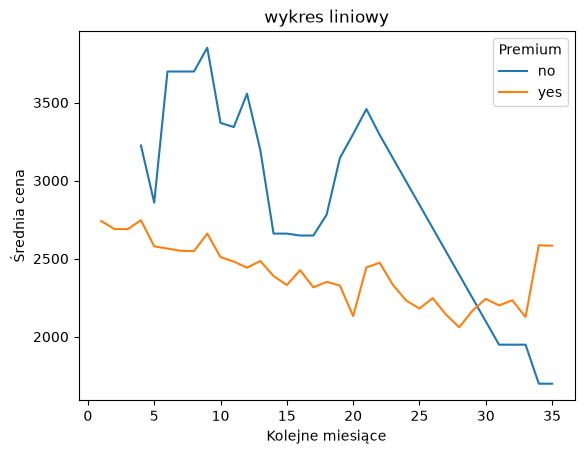

In [172]:
summary = (
    df_copy[df_copy["screen"] >= 15]
    .groupby(["trend", "premium"])
    .agg(n=("ram", "count"), mean_price=("price", "mean"))
    .sort_values(by="mean_price", ascending=False)
)

summary[summary["mean_price"] >= 2500]

sns.lineplot(data=summary, x="trend", y="mean_price", hue="premium")
plt.title("wykres liniowy")
plt.xlabel("Kolejne miesiące")
plt.ylabel("Średnia cena")
plt.legend(title="Premium")
plt.show()

Zwykle premium miało tańszą średnią cenę, ale w ostatnich miesiącach marki premium poszły do góry, a marki nie premium spadły, w okolicy 30 miesiąca.

# Zadanie 2

In [100]:
df = pd.read_csv(BASE + "Ecdat/Computers.csv").drop(columns="rownames")
dirty = df.copy()
dirty.loc[30, "cd"] = "YES"
dirty.loc[42, "ram"] = 0
dirty.loc[97, "price"] = 192000
dirty.loc[310, "multi"] = "yes"
dirty = pd.concat([dirty, dirty.iloc[[7, 8]]], ignore_index=True)

In [101]:
dirty.info()

<class 'pandas.DataFrame'>
RangeIndex: 6261 entries, 0 to 6260
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   price    6261 non-null   int64
 1   speed    6261 non-null   int64
 2   hd       6261 non-null   int64
 3   ram      6261 non-null   int64
 4   screen   6261 non-null   int64
 5   cd       6261 non-null   str  
 6   multi    6261 non-null   str  
 7   premium  6261 non-null   str  
 8   ads      6261 non-null   int64
 9   trend    6261 non-null   int64
dtypes: int64(7), str(3)
memory usage: 489.3 KB


In [102]:
print(f"BRAKI: \n{dirty.isna().sum()}")
print(f"DUPLIAKTY: {dirty.duplicated().sum()}")
print(f"ZAKRESY: {dirty.describe()}")

BRAKI: 
price      0
speed      0
hd         0
ram        0
screen     0
cd         0
multi      0
premium    0
ads        0
trend      0
dtype: int64
DUPLIAKTY: 78
ZAKRESY:                price        speed           hd          ram       screen  \
count    6261.000000  6261.000000  6261.000000  6261.000000  6261.000000   
mean     2249.900974    52.010382   416.515732     8.284619    14.608529   
std      2467.742167    21.154386   258.554285     5.631734     0.905036   
min       949.000000    25.000000    80.000000     0.000000    14.000000   
25%      1794.000000    33.000000   214.000000     4.000000    14.000000   
50%      2144.000000    50.000000   340.000000     8.000000    14.000000   
75%      2595.000000    66.000000   528.000000     8.000000    15.000000   
max    192000.000000   100.000000  2100.000000    32.000000    17.000000   

               ads        trend  
count  6261.000000  6261.000000  
mean    221.260342    15.922217  
std      74.857908     7.877244  
min  

In [103]:
print(dirty["cd"].value_counts())
print(dirty["multi"].value_counts())
print(dirty["premium"].value_counts())

cd
no     3353
yes    2907
YES       1
Name: count, dtype: int64
multi
no     5387
yes     874
Name: count, dtype: int64
premium
yes    5649
no      612
Name: count, dtype: int64


Wartość spoza zakresu: oraz price ma wartość znacznie odbiegającą od Q3. 
Kategoria spoza słownika: "YES" w kolumnie cd, kolumna ram ma wartość 0 
Duplikaty: 78 zduplikowanych wierszy
Wartość spoza zakresu / wartość odstająca: 192000 jest zbyt duza w kolumnie price, przekracza znacząco Q3
Niepoprawny typ: kolumna cd jest STR, ale 0 to liczba
Brak jawny: brak
Brak niejawny: brak

In [140]:
import pandera.pandas as pa
from pandera.errors import SchemaErrors
from pandera.pandas import Check, Column, DataFrameSchema

schemat = DataFrameSchema(
    {
        "ram": Column(int, Check.isin([2, 4, 8, 16, 24, 32]), nullable=True),
        "screen": Column(int, Check.isin([14, 15, 17]), nullable=True),
        "cd": Column(str, Check.isin(["yes", "no"]), nullable=True),
        "price": Column(float, Check.in_range(500, 6000), nullable=True),
    }
)

try:
    schemat.validate(dirty, lazy=True)
    print("no errors!")
except SchemaErrors as err:
    print(err.failure_cases)

  schema_context column                        check check_number  \
0         Column    ram  isin([2, 4, 8, 16, 24, 32])            0   
1         Column     cd          isin(['yes', 'no'])            0   
2         Column  price          in_range(500, 6000)            0   
3         Column  price             dtype('float64')         None   

  failure_case index  
0            0    42  
1          YES    30  
2       192000    97  
3        int64  None  


Schemat nie wykrył dupliaktów. Ustawienie lazy powoduje, że jest uruchamiane w razie potrzebny, a nie za każdym razem. 

Ze zbioru dirty usunę duplikaty, zanieszczają zbiór 
Dodatkową kategorię YES w cd zamienię na yes, ponieważ miała być tam wartość yes, tylko została źle wpisana
Kolumnę z wartością ram = 0 zamienię na np.nan, jedna kolumna nie wpłynie znacząco i trudniej ją próbować naprawić
W wartość odstającą wpiszę np.nan, aby dokonać imputacji

In [138]:
clean = dirty.copy()

# print(clean.shape)

clean = clean.drop_duplicates()
clean.loc[clean["cd"] == "YES", "cd"] = "yes"

clean = clean[clean["ram"].isin([2, 4, 8, 16, 32])]
clean.loc[clean["price"] >= 6000, "price"] = np.nan

clean = clean.dropna()

print(f"BRAKI:{clean.isna().sum()}")
print(f"WYMIARY:{clean.shape}")

BRAKI:price      0
speed      0
hd         0
ram        0
screen     0
cd         0
multi      0
premium    0
ads        0
trend      0
dtype: int64
WYMIARY:(5884, 10)


In [141]:
try:
    schemat.validate(clean, lazy=True)
    print("no errors!")
except SchemaErrors as err:
    print(err.failure_cases)

no errors!


In [142]:
from sklearn.model_selection import train_test_split

# print(clean.isna().sum())

# clean = clean.dropna()

print(clean)

X = clean[["price", "speed", "hd", "ram", "screen", "ads", "trend", "cd", "multi"]]
y = np.where(clean["premium"] == "yes", True, False)

# print(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=7, stratify=y
)

print(
    f"Wymiary:\nX_TRAIN: {X_train.shape}\nX_TEST: {X_test.shape}\nY_TRAIN: {y_train.shape}\nY_TEST: {y_test.shape}"
)

       price  speed   hd  ram  screen   cd multi premium  ads  trend
0     1499.0     25   80    4      14   no    no     yes   94      1
1     1795.0     33   85    2      14   no    no     yes   94      1
2     1595.0     25  170    4      15   no    no     yes   94      1
3     1849.0     25  170    8      14   no    no      no   94      1
4     3295.0     33  340   16      14   no    no     yes   94      1
...      ...    ...  ...  ...     ...  ...   ...     ...  ...    ...
6253  2154.0     66  850   16      15  yes    no     yes   39     35
6254  1690.0    100  528    8      15   no    no     yes   39     35
6255  2223.0     66  850   16      15  yes   yes     yes   39     35
6257  2195.0    100  850   16      15  yes    no     yes   39     35
6258  2490.0    100  850   16      17  yes    no     yes   39     35

[5884 rows x 10 columns]
Wymiary:
X_TRAIN: (4707, 9)
X_TEST: (1177, 9)
Y_TRAIN: (4707,)
Y_TEST: (1177,)


In [143]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


kolumny_liczbowe = ["price", "speed", "hd", "ram", "screen", "ads", "trend"]
kolumny_kategorie = ["cd", "multi"]

liczbowe = Pipeline(
    [("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
)

kategorie = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(drop="if_binary")),
    ]
)

preprocessor = ColumnTransformer(
    [
        ("numeric", liczbowe, kolumny_liczbowe),
        ("categorical", kategorie, kolumny_kategorie),
    ]
)

preprocessor.fit(X_train)

X_train_processed = preprocessor.transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(f"Wymiary:\nX_TRAIN: {X_train.shape}\nX_TEST: {X_test.shape}")

Wymiary:
X_TRAIN: (4707, 9)
X_TEST: (1177, 9)


In [144]:
kolumny_liczbowe = ["price", "speed", "hd", "ram", "screen", "ads", "trend"]
kolumny_kategorie = ["cd", "multi"]

liczbowe = Pipeline(
    [("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
)

kategorie = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(drop="if_binary")),
    ]
)

preprocessor = ColumnTransformer(
    [
        ("numeric", liczbowe, kolumny_liczbowe),
        ("categorical", kategorie, kolumny_kategorie),
    ]
)

preprocessor.fit(X)

X_train_processed_2 = preprocessor.transform(X_train)
X_test_processed_2 = preprocessor.transform(X_test)

print(f"Wymiary:\nX_TRAIN: {X_train.shape}\nX_TEST: {X_test.shape}")

Wymiary:
X_TRAIN: (4707, 9)
X_TEST: (1177, 9)


In [145]:
print(X_test_processed[0])

print(X_test_processed_2[0])

[-1.76971127 -0.89575935 -0.7956525  -0.78024622 -0.65324941  1.55128999
  0.18607251  0.          0.        ]
[-1.77306589 -0.89348939 -0.79177638 -0.77673043 -0.65456122  1.55322402
  0.19199138  0.          0.        ]


Wartości są inne, bo drugi przypadek był robiony na wiekszym zbiorze. Doszło do przecieku danych i część inforamcji, których model nie powinien widzieć, została wykorzystana podczas skalowania. Podejście drugie, z trenowaniem na X jest niepoprawne. 

# Zadanie 3

In [41]:
import cv2
import matplotlib.pyplot as plt

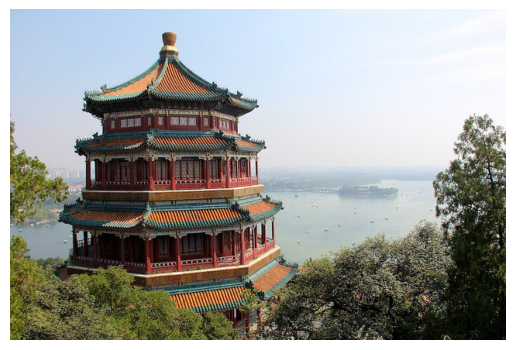

In [ ]:
from sklearn.datasets import load_sample_image

img = load_sample_image("china.jpg")

plt.imshow(img)
plt.axis(False)
plt.show()

In [43]:
print(f"KSZTAŁT:{img.shape}")
print(f"ZAKRES WARTOŚCI:{img.size}")
print(f"LICZBA WARTOŚCI:{img.size}")

KSZTAŁT:(427, 640, 3)
ZAKRES WARTOŚCI:819840
LICZBA WARTOŚCI:819840


KSZTAŁT:(427, 640, 3)
Pierwsza liczba oznacza wysokość, druga liczba oznacza szerokość, natomiast ostatnia liczba oznacza ilość kanałów (Red, Green, Blue)

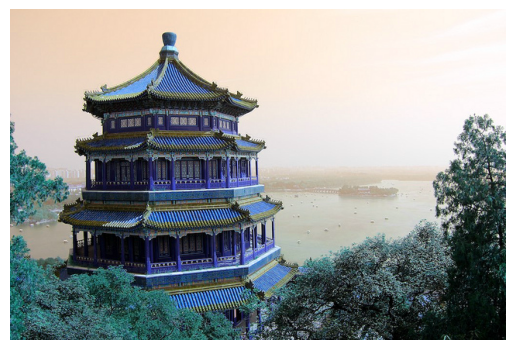

In [48]:
inverted_bgr = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(inverted_bgr)
plt.axis(False)
plt.show()

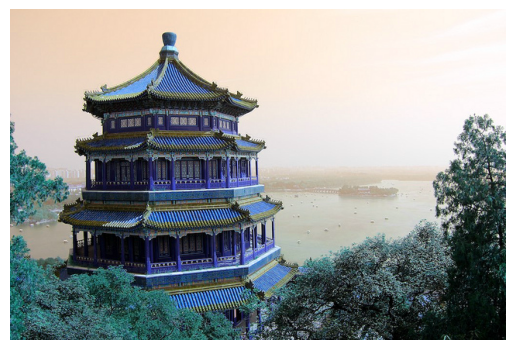

In [ ]:
inverted_bgr_2 = img.copy()

inverted_bgr_2[:, :, 0] = img[:, :, 2]
inverted_bgr_2[:, :, 2] = img[:, :, 0]

plt.imshow(inverted_bgr_2)
plt.axis(False)
plt.show()

In [51]:
np.array_equal(inverted_bgr, inverted_bgr_2)

True

A.HueSaturationValue() i A.ToGray(), spowodują zmianę kolorów, a detekcja ma odbywać się na podstawie kolorów liści

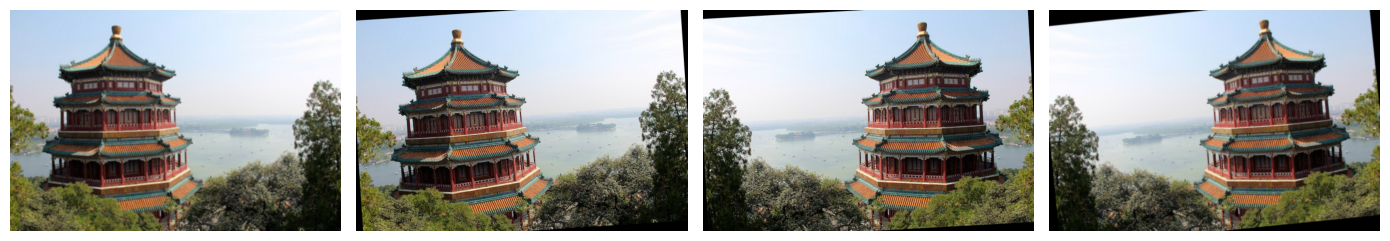

In [52]:
import albumentations as A

pipeline = A.Compose(
    [
        A.HorizontalFlip(p=0.5),
        A.Rotate(limit=10, p=0.5),
        A.GaussianBlur(blur_limit=(3, 5), p=0.3),
    ]
)

fig, axes = plt.subplots(1, 4, figsize=(14, 6.5))
for i, ax in enumerate(axes.flat):
    augmented = pipeline(image=img)["image"]
    ax.imshow(augmented)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [179]:
def cosine_similarity(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))


img_vector = img.astype(np.float32).flatten()
img_bgr_vector = inverted_bgr.astype(np.float32).flatten()

img_flip = img[:, ::-1]
img_roll = np.roll(img, shift=30, axis=1)
img_flower = load_sample_image("flower.jpg")

img_flip_vector = img_flip.astype(np.float32).flatten()
img_roll_vector = img_roll.astype(np.float32).flatten()
img_flower_vector = img_flower.astype(np.float32).flatten()

print(f"A: {round(cosine_similarity(img_vector, img_bgr_vector), 4)}")
print(f"B: {cosine_similarity(img_vector, img_flip_vector).round(4)}")
print(f"C: {cosine_similarity(img_vector, img_roll_vector).round(4)}")
print(f"D: {cosine_similarity(img_vector, img_flower_vector).round(4)}")


A: 0.984000027179718
B: 0.8044999837875366
C: 0.9440000057220459
D: 0.6008999943733215


Podobieństwo kosinususowe nie patrzy na kolory w obrazie a na położenie pixeli, wersja BGR miała zmienione kanały, natomiast położenie pixeli pozostało takie samo, w porównaniu z lustrzanymi odbiciem, gdzie pixele zmieniły swoje położenie